# IEOR 4571 Project

In [18]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date, timedelta

sys.path.insert(0, str(Path.cwd() / "code")) # Add code/ path to system folder

from sandbox import (
    PortfolioEngine,
    YahooFinanceData,
    resample_returns,
)

### Variable Initialization

In [19]:
# Intializing global variables for the analysis
START_DATE = date(2002, 12, 31)
END_DATE = date.today()
TICKERS = ['LQD']

### Data Download

Call the `YahooFinanceData` with initialized ticker and date range, with contents captured in `.data` attribute and store in corresponding `\data` folder.

In [20]:
# Leveraging yfinance to download LQD ETF data from Yahoo Finance
yf_series = YahooFinanceData(ticker=TICKERS, start_date=START_DATE, end_date=END_DATE)
yf_series.fetch_data() # Data stored under .data atribute

yf_series.data.to_csv(f'{os.getcwd()}/data/LQD_Price_Volume.csv')

[*********************100%***********************]  1 of 1 completed


### LQD: iShares Investment-Grade Corporate Bond

Examining the empirical distribution of daily returns, we observe that while the probability mass beyond two standard deviations from the mean is smaller than that of a Gaussian distribution parameterized by the sample mean and variance, the empirical distribution of LQD returns exhibits substantially more pronounced extreme tail realizations. More specifically, the distribution exhibits pronounced leptokurtosis, with an excess kurtosis exceeding 58 and both minimum and maximum daily returns substantially beyond the range typically implied by the fitted Gaussian distribution. These empirical findings are consistent with the established literature documenting departures from normality and the prevalence of fat tails in financial asset return distributions.


In [10]:
lqd_series = yf_series.data["Close"]

KDE tail mass beyond ±2σ: 3.26%
Normal fit tail mass beyond ±2σ: 4.55%
KDE / normal tail-mass ratio: 0.72x


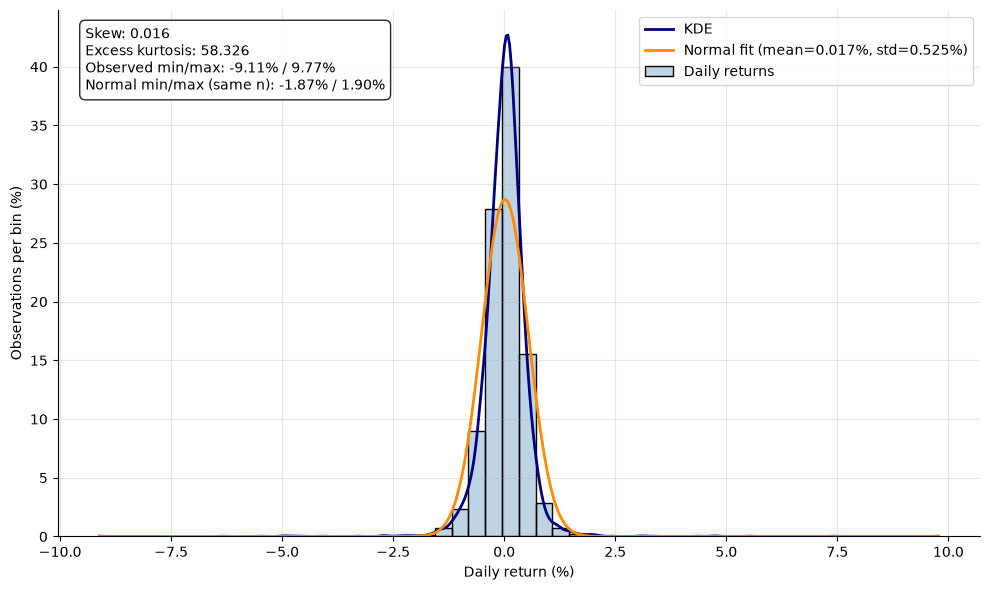

In [ ]:
from scipy.stats import gaussian_kde, norm

close = lqd_series.squeeze()
returns = close.pct_change().dropna()
returns_pct = returns * 100
return_mean = returns_pct.mean()
return_std = returns_pct.std()
skew = float(returns.skew())
excess_kurtosis = float(returns.kurt())
n_returns = len(returns_pct)
observed_min = returns_pct.min()
observed_max = returns_pct.max()
normal_min = norm.ppf(1 / (n_returns + 1), loc=return_mean, scale=return_std)
normal_max = norm.ppf(n_returns / (n_returns + 1), loc=return_mean, scale=return_std)

bin_edges = np.histogram_bin_edges(returns_pct.to_numpy(), bins=50)
bin_width = bin_edges[1] - bin_edges[0]
x = np.linspace(returns_pct.min(), returns_pct.max(), 500)
kde = gaussian_kde(returns_pct.to_numpy())
kde_pct_per_bin = kde(x) * bin_width * 100
normal_pct_per_bin = norm.pdf(x, loc=return_mean, scale=return_std) * bin_width * 100

tail_sigma = 2
lower_tail_threshold = return_mean - tail_sigma * return_std
upper_tail_threshold = return_mean + tail_sigma * return_std
kde_tail_pct = (
    kde.integrate_box_1d(-np.inf, lower_tail_threshold)
    + kde.integrate_box_1d(upper_tail_threshold, np.inf)
) * 100
normal_tail_pct = (
    norm.cdf(lower_tail_threshold, loc=return_mean, scale=return_std)
    + norm.sf(upper_tail_threshold, loc=return_mean, scale=return_std)
) * 100
print(f"KDE tail mass beyond ±{tail_sigma}σ: {kde_tail_pct:.2f}%")
print(f"Normal fit tail mass beyond ±{tail_sigma}σ: {normal_tail_pct:.2f}%")
print(f"KDE / normal tail-mass ratio: {kde_tail_pct / normal_tail_pct:.2f}x")

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    returns_pct,
    bins=bin_edges,
    stat="percent",
    color="steelblue",
    alpha=0.35,
    label="Daily returns",
    ax=ax,
)
ax.plot(x, kde_pct_per_bin, label="KDE", color="navy", linewidth=2)
ax.plot(
    x,
    normal_pct_per_bin,
    label=f"Normal fit (mean={return_mean:.3f}%, std={return_std:.3f}%)",
    color="darkorange",
    linewidth=2,
)

ax.text(
    0.03, 0.97,
    f"Skew: {skew:.3f}\nExcess kurtosis: {excess_kurtosis:.3f}\n"
    f"Observed min/max: {observed_min:.2f}% / {observed_max:.2f}%\n"
    f"Normal min/max (same n): {normal_min:.2f}% / {normal_max:.2f}%",
    transform=ax.transAxes,
    ha="left", va="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85),
)

ax.set(
    xlabel="Daily return (%)",
    ylabel="Observations per bin (%)",
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Trading Strategies

1. **Moving Average Trend Strategy** 
    - General Idea: When a medium term moving average (e.g., 30-day) exceeds a long-term moving average (e.g., 100-day) we initiate a long position and vice versa (i.e., short-position). The assumption is that trends tend to persist whether up / down and thus “riding the wave” is advantageous for a simple strategy.
2. **Relative Strength (RSI) Mean Reversion Strategy** 
    - General Idea: We assume there is a “fair-value” price for a given stock / ETF and assume that short-term price moves will quickly revert back to this “fair-value”. Using RSI we’ll denote overbought / oversold levels as points in which we either sell / buy the underlying asset.
3. **Lagged Short-Term Momentum Strategy** 
    - General idea: Similar in concept to the moving average trend strategy, albeit much shorter duration with the idea hinging on continuing short-momentum in an underlying asset (i.e., if we see three days of higher highs we initiate a long position, and vice versa for shorts).

#### Buy-Hold Portfolio

We test our *control* set against a simple buy-hold strategy for the underlying asset (i.e., perpetually long the asset) 

In [13]:
buy_hold = PortfolioEngine(stock_data=lqd_series, signal_data=pd.Series(1, index=lqd_series.index, name='signal'))
buy_hold.strategy_pnl_creation(signal_lag=0) # Reference the underlying pnl with .strategy_pnl
buy_hold.performance_statistics()

{'Cumulative Total Return': np.float64(160.97697552683184),
 'Annualized Return': np.float64(0.040950326811142856),
 'Annualized Volatility': np.float64(0.0833069814587627),
 'Sharpe Ratio': np.float64(0.49155936386212046),
 'Calmar Ratio': np.float64(0.1640973788604197),
 'Max Drawdown': np.float64(-0.24954893914530452),
 'Average Drawdown': np.float64(-0.04061470460192961),
 'Hit Ratio': 0.5338320864505404}

#### Moving Average Strategy

PROVIDE DETAIL SUMMARY OF THE METHODLOGY USED

In [14]:
def moving_avg_signal(prices: pd.Series, fast_window: int, slow_window: int,
                      mode: str = 'long_short', ma_type: str = 'sma') -> pd.Series:
    '''
    Target position decided at the CLOSE of each day.

    +1 when the fast MA is above the slow MA.
    When it is below: -1 if mode == 'long_short', 0 (cash) if mode == 'long_flat'.
    0 while the slow MA is still warming up.
    '''
    if ma_type == 'sma':
        fast = prices.rolling(fast_window).mean()
        slow = prices.rolling(slow_window).mean()
    elif ma_type == 'ema':
        fast = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
    else:
        raise ValueError(f'unknown ma_type: {ma_type}')

    gap = fast - slow
    below = -1 if mode == 'long_short' else 0
    signal = np.where(gap > 0, 1, np.where(gap < 0, below, 0))   # NaN gap -> 0
    return pd.Series(signal.flatten(), index=prices.index, name='signal')

In [15]:
# Creates single-factor signal to ajoin with price-series
signal = moving_avg_signal(yf_series.data['Close'], fast_window=5, slow_window=90, mode='long_short', ma_type='ema')

In [16]:
strategy = PortfolioEngine(stock_data=lqd_series, signal_data=signal)
strategy.strategy_pnl_creation(signal_lag=1)
strategy.performance_statistics()

{'Cumulative Total Return': np.float64(63.416963144608616),
 'Annualized Return': np.float64(0.02076090820135912),
 'Annualized Volatility': np.float64(0.08292884845007714),
 'Sharpe Ratio': np.float64(0.25034603264576993),
 'Calmar Ratio': np.float64(0.06501325385080531),
 'Max Drawdown': np.float64(-0.3193334738944459),
 'Average Drawdown': np.float64(-0.0723231798192231),
 'Hit Ratio': 0.5178872764090449}

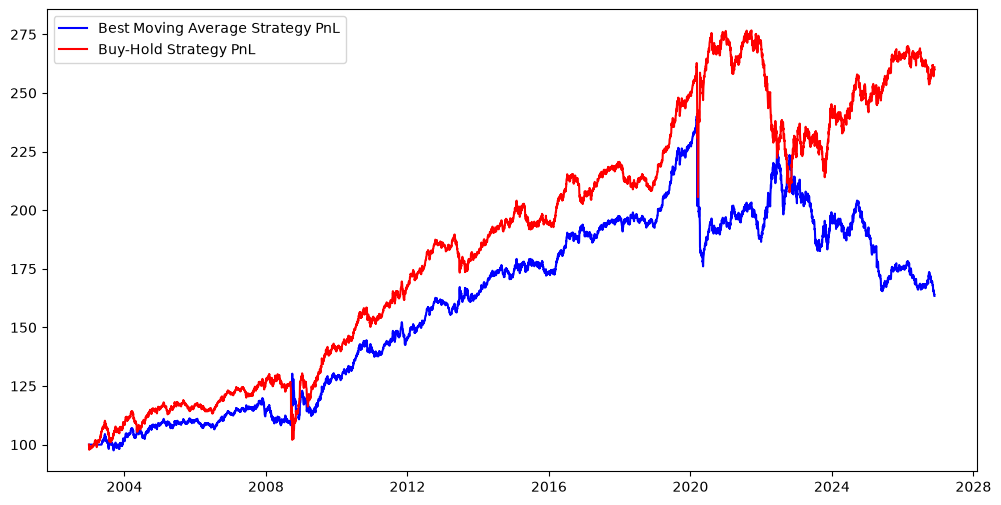

In [17]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(strategy.strategy_pnl['pnl'], label='Best Moving Average Strategy PnL', color='blue')
ax.plot(buy_hold.strategy_pnl['pnl'], label='Buy-Hold Strategy PnL', color='red')
ax.legend()

plt.show()

#### RSI Strategy

PROVIDE DETAIL SUMMARY OF THE METHODLOGY USED

#### Momentum Strategy

PROVIDE DETAIL SUMMARY OF THE METHODLOGY USED

## Grid Search Approach using Methods

USE ONLY FOR NON-TIME DEPEDENDENT STRATEGIES

In [14]:
TRAIN_TEST_SPLIT = 0.75
NUM_SIM = 10000
MAX_WORKERS = max(1, min(NUM_SIM, (os.cpu_count() or 2) - 1))

In [19]:
print(f'Max Computer Workers: {MAX_WORKERS}')

Max Computer Workers: 15


In [25]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm

fast_windows = np.arange(5, 26, 5)
slow_windows = np.arange(30, 101, 5)
hyperparameters = [(f, s) for f in fast_windows for s in slow_windows]


def _run_simulation(i, prices, hyperparameters):
    n = len(hyperparameters)
    train_results = [0] * n
    test_results = [0] * n

    for idx, (f, s) in enumerate(hyperparameters):
        train_, test_returns = resample_returns(
            price_series=prices,
            train_test_split=TRAIN_TEST_SPLIT,
        )
        test_ = (1 + test_returns).cumprod() * 100

        train_signal = moving_avg_signal(
            train_.iloc[:, 0], fast_window=f, slow_window=s,
            mode='long_short', ma_type='ema',
        )
        train_strategy = PortfolioEngine(
            stock_data=train_, signal_data=train_signal.to_frame(),
        )
        train_strategy.strategy_pnl_creation(signal_lag=1)
        train_output = train_strategy.performance_statistics()
        train_output['hyper_parameter'] = (f, s)

        test_signal = moving_avg_signal(
            test_.iloc[:, 0], fast_window=f, slow_window=s,
            mode='long_short', ma_type='ema',
        )
        test_strategy = PortfolioEngine(
            stock_data=test_, signal_data=test_signal.to_frame(),
        )
        test_strategy.strategy_pnl_creation(signal_lag=1)
        test_output = test_strategy.performance_statistics()
        test_output['hyper_parameter'] = (f, s)

        train_results[idx] = train_output
        test_results[idx] = test_output

    return i, train_results, test_results


prices = yf_series.data['Close']
simulation_results = Parallel(
    n_jobs=MAX_WORKERS,
    backend='loky',
    return_as='generator_unordered',
)(
    delayed(_run_simulation)(i, prices, hyperparameters)
    for i in range(NUM_SIM)
)

train_Y = {}
test_Y = {}
for i, train_results, test_results in tqdm(
    simulation_results, total=NUM_SIM, desc='Simulations',
):
    train_Y[i] = train_results
    test_Y[i] = test_results

Simulations: 100%|██████████| 10000/10000 [31:03<00:00,  5.37it/s] 


In [31]:
training_output = pd.concat([pd.DataFrame(train_Y[i]) for i in train_Y])
testing_output = pd.concat([pd.DataFrame(test_Y[i]) for i in test_Y])

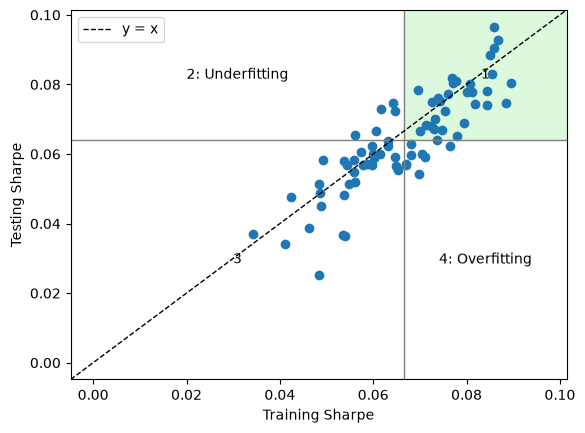

In [41]:
# Average Sharpe ratio per hyper-parameter
y1 = training_output.groupby('hyper_parameter')['Sharpe Ratio'].mean()
y2 = testing_output.groupby('hyper_parameter')['Sharpe Ratio'].mean()
sharpe_comparison = y1.rename('Training Sharpe').to_frame().join(
    y2.rename('Testing Sharpe')
)

fig, ax = plt.subplots()
ax.scatter(sharpe_comparison['Training Sharpe'],
           sharpe_comparison['Testing Sharpe'], zorder=2)

centroid_x = sharpe_comparison['Training Sharpe'].mean()
centroid_y = sharpe_comparison['Testing Sharpe'].mean()
lower = min(sharpe_comparison.min().min(), 0)
upper = max(sharpe_comparison.max().max(), 0)
padding = (upper - lower) * 0.05 or 1
lower -= padding
upper += padding
ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)

# Shade quadrant 1: above-average training and testing Sharpe.
ax.fill_between([centroid_x, upper], [centroid_y, centroid_y], [upper, upper],
                color='lightgreen', alpha=0.3, zorder=0)
ax.axhline(centroid_y, color='gray', linewidth=1)
ax.axvline(centroid_x, color='gray', linewidth=1)
ax.plot([lower, upper], [lower, upper], linestyle='--',
        color='black', linewidth=1, label='y = x')

ax.text((centroid_x + upper) / 2, (centroid_y + upper) / 2, '1',
        ha='center', va='center')
ax.text((lower + centroid_x) / 2, (centroid_y + upper) / 2,
        '2: Underfitting', ha='center', va='center')
ax.text((lower + centroid_x) / 2, (lower + centroid_y) / 2, '3',
        ha='center', va='center')
ax.text((centroid_x + upper) / 2, (lower + centroid_y) / 2,
        '4: Overfitting', ha='center', va='center')

ax.set_xlabel('Training Sharpe')
ax.set_ylabel('Testing Sharpe')
ax.legend()
plt.show()

In [44]:
sharpe_comparison['total_sharpe'] = sharpe_comparison['Training Sharpe'] + sharpe_comparison['Testing Sharpe']
sharpe_comparison.sort_values(by='total_sharpe')

,Training Sharpe,Testing Sharpe,total_sharpe
hyper_parameter,,,
"(5, 30)",0.034145,0.036966,0.071111
"(15, 30)",0.048403,0.025262,0.073665
"(10, 30)",0.041073,0.034102,0.075175
"(10, 35)",0.046256,0.038627,0.084883
"(5, 35)",0.042419,0.047738,0.090157
...,...,...,...
"(20, 95)",0.089495,0.080336,0.169830
"(25, 90)",0.085024,0.088573,0.173597
"(25, 95)",0.085918,0.090418,0.176337
